<a href="https://colab.research.google.com/github/cmd0850/machine_lerning/blob/main/Dzhenchako_lb3_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [2]:
# Ваш код:
# Імпортуйте pandas, numpy, matplotlib.pyplot, seaborn та інші потрібні бібліотеки.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os


## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [3]:
# Ваш код:
# Завантажте файл і збережіть дані у DataFrame `df`.

from google.colab import files
uploaded = files.upload()

df = pd.read_csv("house_price_regression_dataset.csv")
df.head()

Saving house_price_regression_dataset.csv to house_price_regression_dataset.csv


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [25]:
# Ваш код:
# Завантажте датасет з Kaggle та створіть DataFrame `df`.

path=kagglehub.dataset_download('prokshitha/home-value-insights')
df=pd.read_csv(os.path.join(path, "house_price_regression_dataset.csv"))
df

Using Colab cache for faster access to the 'home-value-insights' dataset.


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06
...,...,...,...,...,...,...,...,...
995,3261,4,1,1978,2.165110,2,10,7.014940e+05
996,3179,1,2,1999,2.977123,1,10,6.837232e+05
997,2606,4,2,1962,4.055067,0,2,5.720240e+05
998,4723,5,2,1950,1.930921,0,7,9.648653e+05


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [26]:
# Ваш код:
# Виведіть кілька перших рядків та загальну інформацію про DataFrame.

print("Перші рядки", df.head, '\n\nЗагальна інформація\n', df.info)



Перші рядки <bound method NDFrame.head of      Square_Footage  Num_Bedrooms  Num_Bathrooms  Year_Built  Lot_Size  \
0              1360             2              1        1981  0.599637   
1              4272             3              3        2016  4.753014   
2              3592             1              2        2016  3.634823   
3               966             1              2        1977  2.730667   
4              4926             2              1        1993  4.699073   
..              ...           ...            ...         ...       ...   
995            3261             4              1        1978  2.165110   
996            3179             1              2        1999  2.977123   
997            2606             4              2        1962  4.055067   
998            4723             5              2        1950  1.930921   
999            3268             4              2        1983  3.108790   

     Garage_Size  Neighborhood_Quality   House_Price  
0             

### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [27]:
# Ваш код:
# Порахуйте кількість дублікатів.
df.duplicated().sum()




np.int64(0)

### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [28]:
# Ваш код:
# Виведіть кількість пропусків для кожної ознаки.

df.isna().sum()



,0
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [29]:
# Ваш код:
# Отримайте описову статистику датасету.


df.describe()


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [30]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Neighborhood_Quality`.
df['Neighborhood_Quality'].value_counts()




,count
Neighborhood_Quality,
10,123
5,109
2,105
7,102
6,101
4,99
8,97
1,91
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

<Axes: xlabel='Neighborhood_Quality', ylabel='count'>

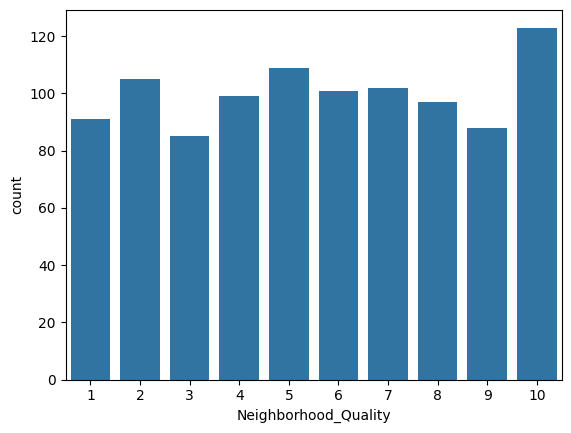

In [31]:
# Ваш код:
# Побудуйте countplot або іншу відповідну діаграму.


sns.countplot(data=df, x='Neighborhood_Quality')

### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [32]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Num_Bathrooms`.
df['Num_Bathrooms'].value_counts()




,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

<Axes: xlabel='Num_Bathrooms', ylabel='count'>

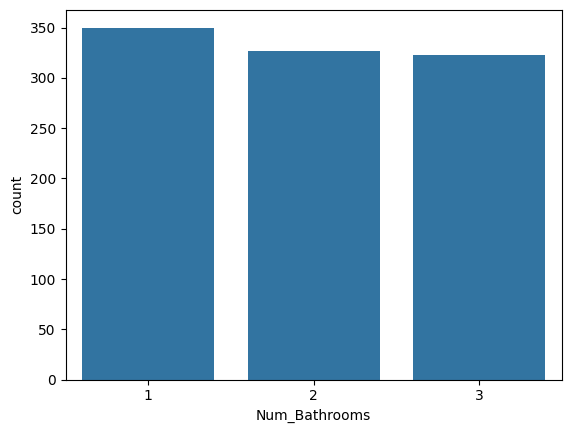

In [33]:
# Ваш код:
# Побудуйте відповідну діаграму.

sns.countplot(data=df, x='Num_Bathrooms')





### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

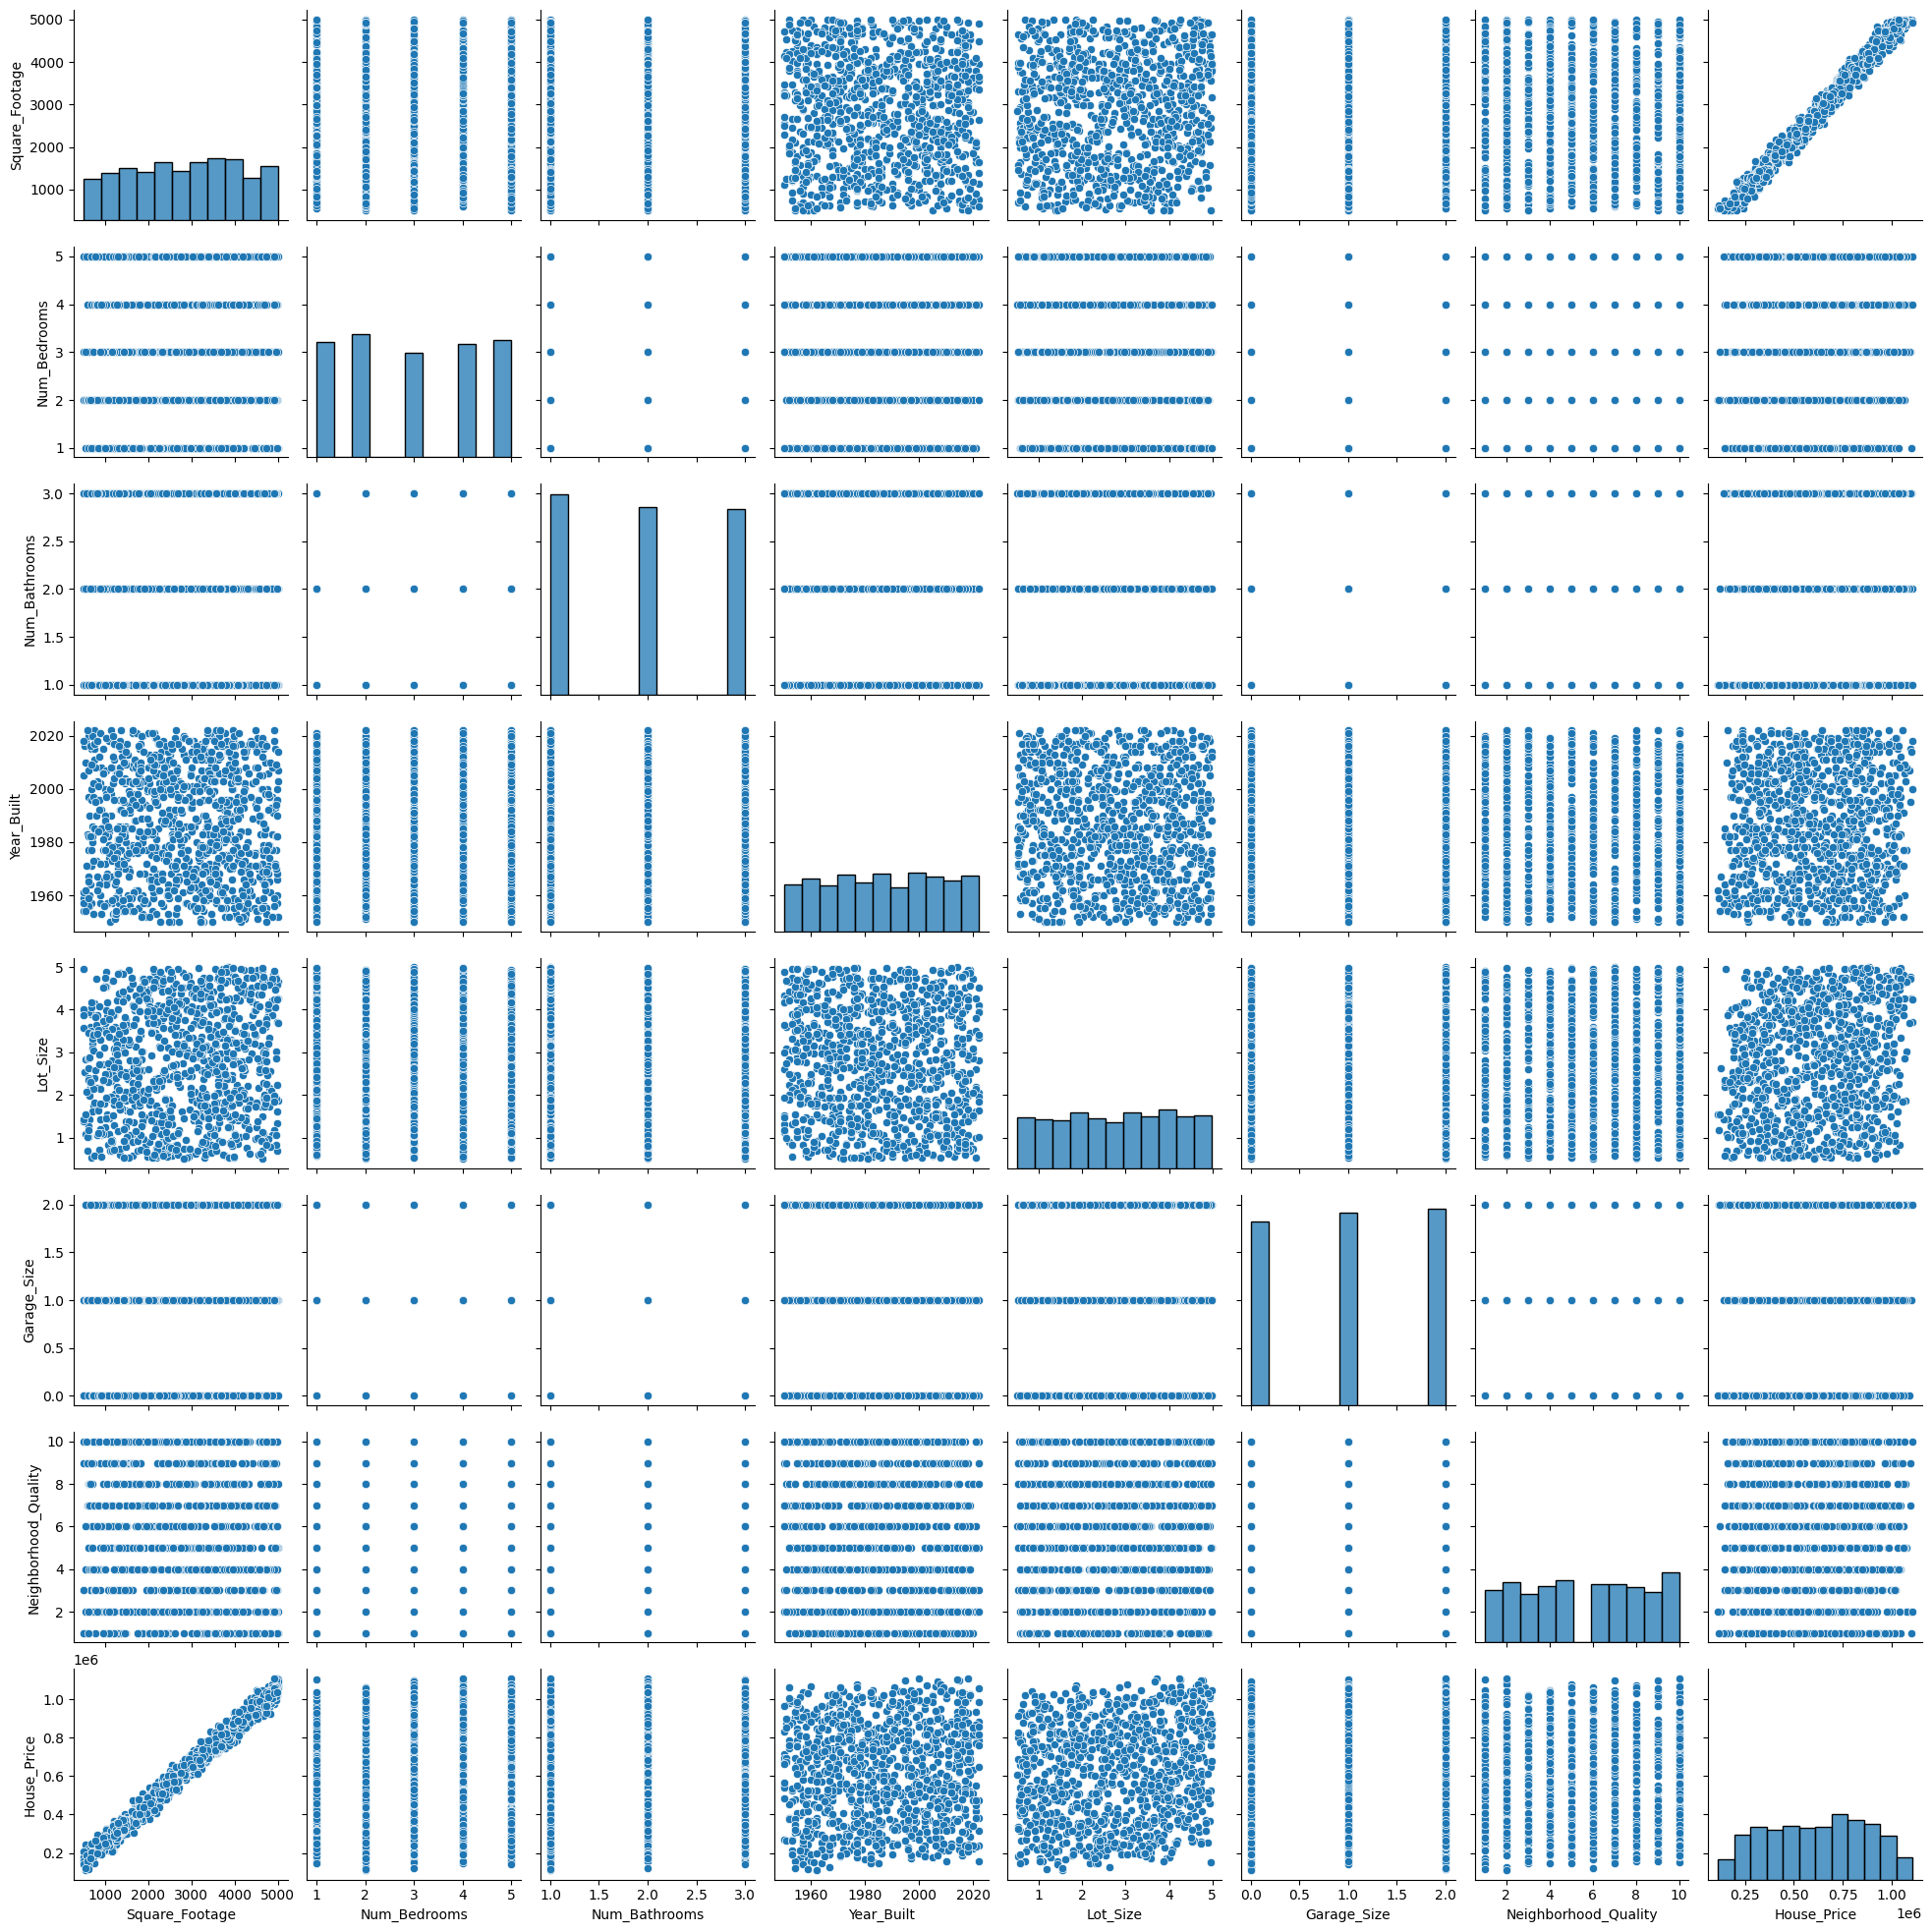

In [34]:
# Ваш код:
# Побудуйте pairplot або іншу попарну візуалізацію.

sns.pairplot(df)



## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

<Axes: >

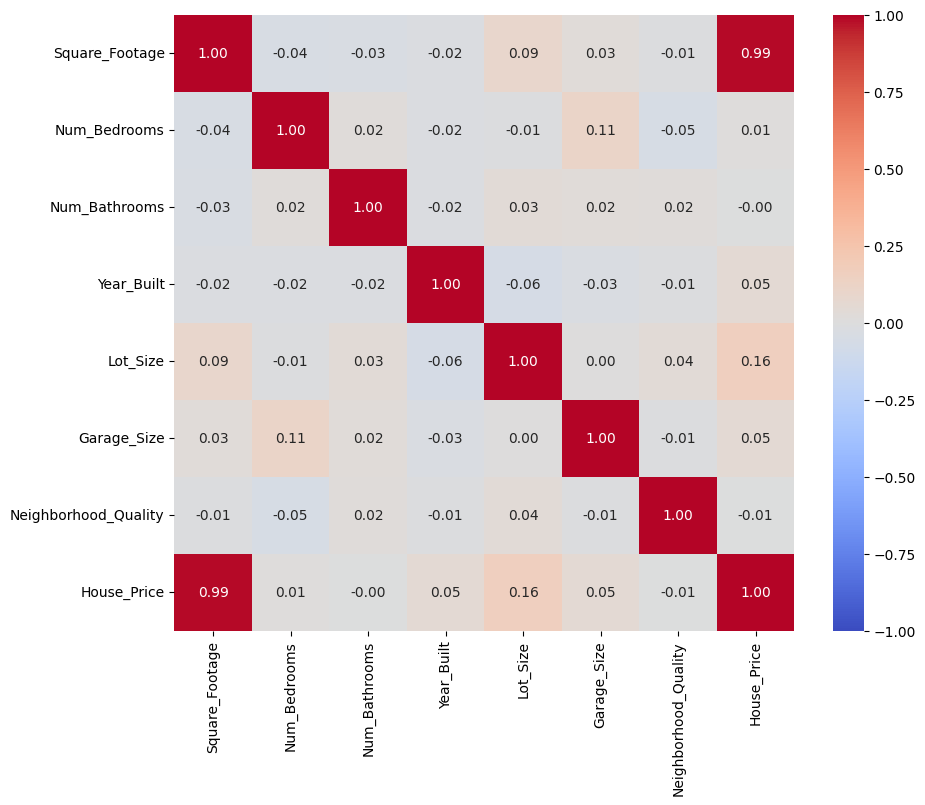

In [35]:
# Ваш код:
# Обчисліть кореляційну матрицю та побудуйте heatmap.
corr = df.corr(numeric_only=True)


plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)



### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [36]:
# Ваш код:
# Виведіть кореляції ознак із `House_Price`.


df.corr(numeric_only=True)['House_Price'].sort_values(ascending=False)


,House_Price
House_Price,1.000000
Square_Footage,0.991261
Lot_Size,0.160412
Garage_Size,0.052133
Year_Built,0.051967
Num_Bedrooms,0.014633
Num_Bathrooms,-0.001862
Neighborhood_Quality,-0.007770


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [37]:
# Ваш код:
# Імпортуйте необхідні класи та функції зі scikit-learn.
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from sklearn.pipeline import Pipeline




### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [38]:
# Ваш код:
# Створіть `X` та `y`.
x=df.drop('House_Price', axis=1)
y=df['House_Price']




### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [40]:
# Ваш код:
# Створіть `X_train`, `X_test`, `y_train`, `y_test`.

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [41]:
# Ваш код:
# Створіть словник або іншу структуру з п’ятьма моделями.

models={
    'linear regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())]),
    'Ridge': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(random_state=42))]),
    'Lasso': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Lasso(random_state=42))]),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}



### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [43]:
# Ваш код:
# Навчіть усі моделі, отримайте прогнози та метрики на тестовій вибірці.

results={}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    r2=r2_score(y_test, y_pred)
    mae=mean_absolute_error(y_test, y_pred)
    mse=mean_squared_error(y_test, y_pred)
    results[name]={
        'r2': r2,
        "mae": mae,
        'mse': mse
    }

print(results)

{'linear regression': {'r2': 0.9984263636823413, 'mae': 8174.583600006616, 'mse': 101434798.50563587}, 'Ridge': {'r2': 0.9984101333060926, 'mae': 8241.586910533184, 'mse': 102480990.00870743}, 'Lasso': {'r2': 0.9984263363831538, 'mae': 8174.748373814552, 'mse': 101436558.18006425}, 'Random Forest': {'r2': 0.9938855300068556, 'mae': 16114.289643937647, 'mse': 394131747.44603425}, 'Gradient Boosting': {'r2': 0.9965099350498217, 'mae': 12305.217614870178, 'mse': 224965597.8451496}}


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

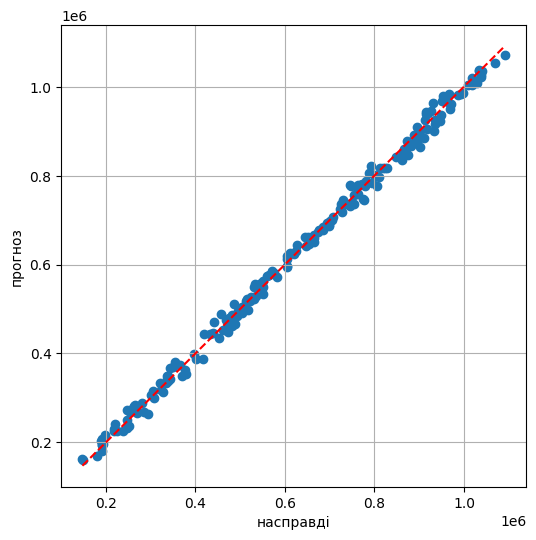

In [44]:
# Ваш код:
# Побудуйте окремий графік для кожної моделі.

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, label='предікшн')
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         'r--'
)

plt.xlabel('насправді')
plt.ylabel('прогноз')
plt.grid(True)
plt.show()

## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [45]:
# Ваш код:
# Створіть сітку параметрів, GridSearchCV і знайдіть найкращі параметри.


param_grid = {
    "n_estimators": [100, 200],
    "max_features": ["sqrt", 0.5, 1.0],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
}

grid = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("Найкращі :", grid.best_params_)
print("Найкращий R2:", grid.best_score_)


Fitting 5 folds for each of 54 candidates, totalling 270 fits
Найкращі : {'max_depth': None, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 200}
Найкращий R2: 0.9919663079158397


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [55]:
# Ваш код:
# Навчіть оптимізований Random Forest та обчисліть метрики.


best_rf = RandomForestRegressor(**grid.best_params_, random_state=42)
best_rf.fit(X_train, y_train)

y_pred = best_rf.predict(X_test)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)

print(f"R²:", r2)
print(f"MAE:", mae)
print(f"MSE:", mse)



R²: 0.9939926162295505
MAE: 16035.16807954079
MSE: 387229091.9214415


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [56]:
# Ваш код:
# Виведіть результати двох моделей у зручному для порівняння вигляді.

base=RandomForestRegressor(random_state=42)
base.fit(X_train, y_train)
y_pred_base=base.predict(X_test)

y_pred_best = best_rf.predict(X_test)

comparison = pd.DataFrame({
    "Базова": [
        r2_score(y_test, y_pred_base),
        mean_absolute_error(y_test, y_pred_base),
        mean_squared_error(y_test, y_pred_base),
    ],
    "Оптимізована": [
        r2_score(y_test, y_pred_best),
        mean_absolute_error(y_test, y_pred_best),
        mean_squared_error(y_test, y_pred_best),
    ],
}, index=["R²", "MAE", "MSE"])

comparison["Різниця"] = comparison["Оптимізована"] - comparison["Базова"]
print(comparison)



           Базова  Оптимізована       Різниця
R²   9.938855e-01  9.939926e-01  1.070862e-04
MAE  1.611429e+04  1.603517e+04 -7.912156e+01
MSE  3.941317e+08  3.872291e+08 -6.902656e+06


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

Так, якість змінилась, але дуже незначною мірою. Усі три метрики змінилися, і з них MSE нає найбльшу різницю. Використання оптимізованох моделі доцільно, але ефект незначний.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [60]:
# Ваш код:
# Сформуйте DataFrame з фактичними та прогнозованими значеннями і розрахуйте похибку у %.

lr=models["linear regression"]

table=pd.DataFrame({
    "Фактична ціна": y_test.values,
    "Прогнозована ціна": y_pred_lr,
})
table["Похибка, %"]=(table["Прогнозована ціна"]-table["Фактична ціна"]).abs()/table["Фактична ціна"]*100

table.sample(10, random_state=42).round(2)



,Фактична ціна,Прогнозована ціна,"Похибка, %"
95,1068538.11,1059729.02,0.82
15,194353.74,187868.55,3.34
30,270230.64,279715.82,3.51
158,986006.86,981949.27,0.41
128,953339.73,957382.95,0.42
115,914555.75,909764.27,0.52
69,746167.73,742469.14,0.50
170,646766.29,654445.55,1.19
174,523323.07,524605.44,0.25
45,1008539.16,1011343.64,0.28


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**